
# Portfolio Construction and Optimization

## 1. Top Down Investment Approach

Our Investment Team suggests Kappa Foundation to follow a top-down approach in selecting suitable investments for its growth portfolio.

The process begins with economic conditions, followed by sector analysis and individual stock selection.

### Economic Considerations

As of December 2022, the US investment environment was influenced by high inflation, rising interest rates, and uncertainty about economic growth.

These conditions affect industries differently. Defensive sectors may provide more stable earnings, while growth-oriented and cyclical sectors may offer higher return potential but greater volatility.

### Approach workflow

The portfolio selection process follows:

**Economic Environment → Sector Analysis → Company Screening → Candidate Universe**

The objective is to identify financially sound companies across different sectors while balancing growth potential, investment risk, and diversification.


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

pd.set_option("display.float_format", "{:,.4f}".format)

PROJECT_NAME = "Kappa_Foundation_1"
cwd = Path.cwd().resolve()

matches = [
    p for p in (cwd, *cwd.parents)
    if p.name == PROJECT_NAME
]

if not matches:
    raise FileNotFoundError(
        "Open Kappa_Foundation_1 in VS Code."
    )

PROJECT_ROOT = matches[0]

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"


# Define portable data directories.
DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

# Create directories if they do not exist.
for directory in [RAW_DIR, PROCESSED_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

for folder in [PROCESSED_DIR, TABLES_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Task 3 environment ready.")


Task 3 environment ready.


## 2. Sector ETF Analysis

Eight US sector ETFs are used to evaluate historical sector performance from January 2015 to December 2022.

| Sector | Representative ETF |
|---|---|
| Technology | XLK |
| Health Care | XLV |
| Financials | XLF |
| Energy | XLE |
| Consumer Discretionary | XLY |
| Consumer Staples | XLP |
| Utilities | XLU |
| Industrials | XLI |

SPY would be used as the broad US equity market benchmark. Each sector is evaluated using annualized return, volatility, CAGR, Sharpe Ratio, maximum drawdown, and correlation with SPY.


In [3]:

import json
import yfinance as yf
from datetime import datetime, timezone

SECTOR_RAW_DIR = PROJECT_ROOT / "data" / "raw" / "sectors"
SECTOR_OUTPUT_DIR = TABLES_DIR / "sectors"

SECTOR_RAW_DIR.mkdir(parents=True, exist_ok=True)
SECTOR_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SECTOR_MAP = {
    "Technology": "XLK",
    "Health Care": "XLV",
    "Financials": "XLF",
    "Energy": "XLE",
    "Consumer Discretionary": "XLY",
    "Consumer Staples": "XLP",
    "Utilities": "XLU",
    "Industrials": "XLI"
}

ORIGINAL_SECTORS = [
    "Technology",
    "Health Care",
    "Financials",
    "Energy",
    "Consumer Discretionary"
]

SECTOR_TICKERS = list(SECTOR_MAP.values()) + ["SPY"]

DATA_MODE = "download"
RAW_FILE = SECTOR_RAW_DIR / "sector_yahoo_raw.pkl"
METADATA_FILE = SECTOR_RAW_DIR / "metadata.json"

if DATA_MODE == "download":

    if RAW_FILE.exists():
        raise FileExistsError(
            "Raw data already exist. Use offline mode "
            "to avoid overwriting the original download."
        )

    sector_raw = yf.download(
        SECTOR_TICKERS,
        start="2014-12-01",
        end="2023-01-01",
        interval="1d",
        auto_adjust=True,
        actions=True,
        threads=False,
        progress=False
    )

    if sector_raw.empty:
        raise ValueError("No sector data downloaded.")

    sector_raw.to_pickle(RAW_FILE)

    metadata = {
        "source": "Yahoo Finance via yfinance",
        "retrieved_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "tickers": SECTOR_TICKERS,
        "start": "2014-12-01",
        "end_exclusive": "2023-01-01",
        "interval": "1d",
        "auto_adjust": True,
        "actions": True,
        "yfinance_version": yf.__version__
    }

    with open(METADATA_FILE, "w") as file:
        json.dump(metadata, file, indent=4)

elif DATA_MODE == "offline":

    if not RAW_FILE.exists():
        raise FileNotFoundError(
            "Sector raw data missing. Run download mode first."
        )

    sector_raw = pd.read_pickle(RAW_FILE)

else:
    raise ValueError("Invalid DATA_MODE.")

print("Sector data loaded successfully.")
print("Raw observations:", len(sector_raw))


Sector data loaded successfully.
Raw observations: 2036


In [4]:
# Construct month-end adjusted prices.

sector_prices = sector_raw["Close"].copy()
sector_prices = sector_prices.reindex(columns=SECTOR_TICKERS)

sector_monthly_prices = (
    sector_prices.resample("ME").last()
)

sector_returns = (
    sector_monthly_prices
    .pct_change(fill_method=None)
    .loc["2015-01":"2022-12"]
)

if sector_returns.shape != (96, 9):
    raise ValueError(
        f"Unexpected data shape: {sector_returns.shape}"
    )

if sector_returns.isna().any().any():
    raise ValueError("Missing sector returns detected.")

sector_returns.index = sector_returns.index.to_period("M")
sector_returns.index.name = "Month"

sector_returns.to_csv(
    PROCESSED_DIR / "sector_monthly_returns.csv"
)

print("Monthly sector returns:", sector_returns.shape)
display(sector_returns.head())


Monthly sector returns: (96, 9)


Ticker,XLK,XLV,XLF,XLE,XLY,XLP,XLU,XLI,SPY
Month,,,,,,,,,
2015-01,-0.0351,0.0130,-0.0696,-0.0456,-0.0299,-0.0097,0.0233,-0.0355,-0.0296
2015-02,0.0799,0.0429,0.0582,0.0459,0.0854,0.0414,-0.0639,0.0535,0.0562
2015-03,-0.0344,0.0064,-0.0062,-0.0116,-0.0048,-0.0194,-0.0100,-0.0255,-0.0157
2015-04,0.0275,-0.0109,0.0008,0.0657,-0.0005,-0.0076,-0.0047,-0.0025,0.0098
2015-05,0.0186,0.0450,0.0195,-0.0519,0.0131,0.0087,0.0063,0.0032,0.0129



## 3. Historical Sector Performance

Sector performance is evaluated using six measures.

**Annual Return:** Average monthly return multiplied by 12.

**Volatility:** Monthly return standard deviation multiplied by the square root of 12.

**CAGR:** Annualized compound growth over the estimation period.

**Sharpe Ratio:** Annualized excess return divided by annualized volatility.

$$
SR=\frac{E(R)-R_f}{\sigma}
$$

**Maximum Drawdown:** The largest historical decline from a previous portfolio peak.

**Correlation with SPY:** The extent to which each sector ETF moves with the broad equity market.

These measures capture different aspects of performance and risk. No single measure determines the final sector selection.


In [ ]:
# Load historical monthly risk-free rates.

factor_data = pd.read_csv(
    PROCESSED_DIR / "ff3_factors_estimation.csv",
    index_col="Month"
)

factor_data.index = pd.PeriodIndex(
    factor_data.index,
    freq="M"
)

rf = factor_data["RF"].reindex(sector_returns.index)

if rf.isna().any():
    raise ValueError("Missing risk-free observations.")

def max_drawdown(r):
    wealth = pd.concat([
        pd.Series([1.0]),
        (1 + r).cumprod().reset_index(drop=True)
    ], ignore_index=True)

    return (wealth / wealth.cummax() - 1).min()

def annual_sharpe(r, rf):
    excess = r - rf
    return (
        excess.mean() / r.std(ddof=1) * np.sqrt(12)
    )

sector_records = []

for sector, ticker in SECTOR_MAP.items():

    r = sector_returns[ticker]

    sector_records.append({
        "Sector": sector,
        "ETF": ticker,
        "Suitable Sector": sector in ORIGINAL_SECTORS,
        "Annual Return": r.mean() * 12,
        "Annual Volatility": r.std(ddof=1) * np.sqrt(12),
        "CAGR": (1 + r).prod() ** (12 / len(r)) - 1,
        "Sharpe Ratio": annual_sharpe(r, rf),
        "Max Drawdown": max_drawdown(r),
        "2022 Return": (1 + r.loc["2022"]).prod() - 1,
        "Correlation with SPY":
            r.corr(sector_returns["SPY"])
    })

sector_performance = (
    pd.DataFrame(sector_records)
    .sort_values("Sharpe Ratio", ascending=False)
    .reset_index(drop=True)
)

display(sector_performance.round(4))

sector_performance.to_csv(
    SECTOR_OUTPUT_DIR / "T3_sector_performance.csv",
    index=False
)


,Sector,ETF,Team Original,Annual Return,Annual Volatility,CAGR,Sharpe Ratio,Max Drawdown,2022 Return,Correlation with SPY
0,Technology,XLK,True,0.1709,0.1943,0.1634,0.8363,-0.3121,-0.2773,0.9233
1,Health Care,XLV,True,0.1134,0.1483,0.1076,0.7076,-0.1321,-0.0208,0.8117
2,Consumer Staples,XLP,False,0.0890,0.1306,0.0836,0.6163,-0.1363,-0.0081,0.7229
3,Utilities,XLU,False,0.0947,0.1516,0.0865,0.5688,-0.1887,0.0144,0.4710
4,Industrials,XLI,False,0.1067,0.1923,0.0920,0.5110,-0.2715,-0.0557,0.9230
5,Financials,XLF,True,0.1072,0.2031,0.0900,0.4859,-0.3179,-0.1059,0.8665
6,Consumer Discretionary,XLY,True,0.1046,0.1991,0.0886,0.4829,-0.3627,-0.3627,0.9149
7,Energy,XLE,True,0.1060,0.3226,0.0558,0.3024,-0.5821,0.6432,0.6520



## 4. Five-Sector Portfolio Comparison

Our team selection includes Technology, Health Care, Financials, Energy, and Consumer Discretionary.

To evaluate this choice, all possible five-sector combinations from the eight sector ETFs are compared.

Each combination is equally weighted at 20% per sector.

The analysis compares annualized return, volatility, Sharpe Ratio, maximum drawdown, and mean-variance utility:

$$
U=E(R_p)-\frac{A}{2}\sigma_p^2
$$
Risk-aversion coefficients of $$(A=1,3,5)$$ are examined.

In [6]:
from itertools import combinations

SECTOR_NAMES = list(SECTOR_MAP.keys())

def sector_portfolio_metrics(sectors):

    tickers = [SECTOR_MAP[s] for s in sectors]

    # Equal-weight sector portfolio
    r = sector_returns[tickers].mean(axis=1)

    mu = r.mean() * 12
    sigma = r.std(ddof=1) * np.sqrt(12)

    result = {
        "Sectors": ", ".join(sectors),
        "Annual Return": mu,
        "Volatility": sigma,
        "Sharpe Ratio": annual_sharpe(r, rf),
        "Max Drawdown": max_drawdown(r)
    }

    for A in [1, 3, 5]:
        result[f"Utility A={A}"] = (
            mu - 0.5 * A * sigma**2
        )

    return result


sector_combinations = pd.DataFrame([
    sector_portfolio_metrics(combo)
    for combo in combinations(SECTOR_NAMES, 5)
])

sector_combinations = (
    sector_combinations
    .sort_values("Utility A=3", ascending=False)
    .reset_index(drop=True)
)

sector_combinations.insert(
    0, "Rank A=3",
    np.arange(1, len(sector_combinations) + 1)
)

# Locate the team's original selection.
original_set = set(ORIGINAL_SECTORS)

original_result = sector_combinations[
    sector_combinations["Sectors"].apply(
        lambda x: set(x.split(", ")) == original_set
    )
].copy()

assert len(sector_combinations) == 56
assert len(original_result) == 1

print("Top five sector combinations:")
display(sector_combinations.head(5).round(4))

print("Team's original sector selection:")
display(original_result.round(4))

sector_combinations.to_csv(
    SECTOR_OUTPUT_DIR / "T3_sector_combinations.csv",
    index=False
)


Top five sector combinations:


,Rank A=3,Sectors,Annual Return,Volatility,Sharpe Ratio,Max Drawdown,Utility A=1,Utility A=3,Utility A=5
0,1,"Technology, Health Care, Financials, Consumer ...",0.1150,0.1334,0.7987,-0.1760,0.1061,0.0883,0.0705
1,2,"Technology, Health Care, Consumer Staples, Uti...",0.1150,0.1353,0.7871,-0.1692,0.1058,0.0875,0.0692
2,3,"Technology, Health Care, Consumer Discretionar...",0.1145,0.1362,0.7785,-0.1864,0.1053,0.0867,0.0681
3,4,"Technology, Health Care, Financials, Utilities...",0.1186,0.1479,0.7445,-0.2029,0.1077,0.0858,0.0639
4,5,"Technology, Health Care, Financials, Consumer ...",0.1182,0.1478,0.7420,-0.2050,0.1072,0.0854,0.0635


Team's original sector selection:


,Rank A=3,Sectors,Annual Return,Volatility,Sharpe Ratio,Max Drawdown,Utility A=1,Utility A=3,Utility A=5
33,34,"Technology, Health Care, Financials, Energy, C...",0.1205,0.1803,0.6211,-0.2644,0.1042,0.0717,0.0392



### Interpretation of Sector Selection

The team's original five-sector combination ranks 34th out of 56 portfolios at A = 3, with an annual return of 12.05%, volatility of 18.03%, Sharpe Ratio of 0.6211, and maximum drawdown of 26.44%.

Although this combination does not achieve the highest risk-adjusted performance, the team accepts this trade-off to maintain exposure to both defensive and growth-oriented sectors. Technology and Consumer Discretionary provide growth potential, while Health Care, Financials, and Energy offer different sources of earnings and market exposure.

To manage the relatively high sector-level risk, the next stage will focus on selecting stocks with different risk characteristics, financial strength, and correlations. Portfolio optimization will then determine appropriate weights to reduce concentration risk.

Therefore, the sector combination is retained as a candidate universe rather than a final portfolio. Its suitability will depend on whether stock-level diversification and portfolio optimization can improve the risk-return trade-off.



## 5. Company Analysis

Following the sector analysis, 11 US stocks are considered across the five selected sectors.

The analysis evaluates annualized returns, volatility, CAGR, maximum drawdown, Sharpe Ratio, and correlation with SPY.

Each stock is also compared with its representative sector ETF to assess its historical performance relative to the industry.

The objective is to identify companies with different return and risk characteristics that may improve diversification within the growth portfolio.


In [ ]:
# Team's selected stocks and their representative sector ETFs.

STOCK_SECTORS = {
    "AAPL": ("Technology", "XLK"),
    "MSFT": ("Technology", "XLK"),
    "JNJ": ("Health Care", "XLV"),
    "MRK": ("Health Care", "XLV"),
    "UNH": ("Health Care", "XLV"),
    "JPM": ("Financials", "XLF"),
    "V": ("Financials", "XLF"),
    "CVX": ("Energy", "XLE"),
    "XOM": ("Energy", "XLE"),
    "AMZN": ("Consumer Discretionary", "XLY"),
    "MCD": ("Consumer Discretionary", "XLY")
}

STOCKS = list(STOCK_SECTORS.keys())
EQUITY_ETFS = ["SPY", "IWM"]
ALL_ASSETS = STOCKS + EQUITY_ETFS

stock_universe = pd.DataFrame([
    {
        "Ticker": ticker,
        "Sector": sector,
        "Sector ETF": etf
    }
    for ticker, (sector, etf) in STOCK_SECTORS.items()
])

display(stock_universe)

assert len(STOCKS) == 11
assert stock_universe["Sector"].nunique() == 5
assert len(ALL_ASSETS) == 13

print("Company universe initialized.")


,Ticker,Sector,Sector ETF
0,AAPL,Technology,XLK
1,MSFT,Technology,XLK
2,JNJ,Health Care,XLV
3,MRK,Health Care,XLV
4,UNH,Health Care,XLV
5,JPM,Financials,XLF
6,V,Financials,XLF
7,CVX,Energy,XLE
8,XOM,Energy,XLE
9,AMZN,Consumer Discretionary,XLY


Company universe initialized.


In [ ]:
import yfinance as yf
import json
from datetime import datetime, timezone

STOCK_RAW_DIR = PROJECT_ROOT / "data" / "raw" / "company_selection"
STOCK_RAW_DIR.mkdir(parents=True, exist_ok=True)

DATA_MODE = "download"

EXISTING_RAW_DIR = (
    PROJECT_ROOT / "data" / "raw" / "yahoo_finance"
)

raw_series = {}
download_records = []

for ticker in ALL_ASSETS:

    original_file = EXISTING_RAW_DIR / f"{ticker}_daily.csv"
    new_file = STOCK_RAW_DIR / f"{ticker}_daily.csv"

    if original_file.exists():
        file_path = original_file

    elif new_file.exists():
        file_path = new_file

    else:
        if DATA_MODE != "download":
            raise FileNotFoundError(
                f"Missing saved raw data for {ticker}."
            )

        downloaded = yf.download(
            ticker,
            start="2014-12-01",
            end="2023-01-01",
            interval="1d",
            auto_adjust=False,
            actions=False,
            progress=False,
            threads=False,
            multi_level_index=False
        )

        if downloaded.empty or "Adj Close" not in downloaded:
            raise ValueError(
                f"Missing adjusted prices for {ticker}."
            )

        downloaded.to_csv(new_file, index_label="Date")
        file_path = new_file

        download_records.append({
            "ticker": ticker,
            "retrieved_at_utc":
                datetime.now(timezone.utc).isoformat(),
            "source": "Yahoo Finance via yfinance",
            "raw_file": str(file_path.relative_to(PROJECT_ROOT)),
            "start": "2014-12-01",
            "end_exclusive": "2023-01-01",
            "auto_adjust": False,
            "price_field": "Adj Close",
            "yfinance_version": yf.__version__
        })

    data = pd.read_csv(
        file_path,
        index_col="Date",
        parse_dates=True
    )

    if "Adj Close" not in data.columns:
        raise ValueError(
            f"Adjusted Close missing for {ticker}."
        )

    series = pd.to_numeric(
        data["Adj Close"], errors="coerce"
    ).dropna()

    series = series.loc[:"2022-12-31"]

    raw_series[ticker] = series

if download_records:
    record_file = STOCK_RAW_DIR / "download_record.json"

    with open(record_file, "w", encoding="utf-8") as file:
        json.dump(download_records, file, indent=4)

print("All company price files loaded.")
print(f"New downloads: {len(download_records)}")


All company price files loaded.
New downloads: 5


In [9]:
# Construct monthly adjusted closing prices.

monthly_prices = {}

for ticker, daily_prices in raw_series.items():

    monthly = daily_prices.groupby(
        daily_prices.index.to_period("M")
    ).last()

    monthly_prices[ticker] = monthly

monthly_prices = pd.DataFrame(monthly_prices)

monthly_returns = (
    monthly_prices
    .pct_change(fill_method=None)
    .loc["2015-01":"2022-12", ALL_ASSETS]
)

expected_months = pd.period_range(
    "2015-01", "2022-12", freq="M"
)

monthly_returns = monthly_returns.reindex(
    expected_months
)

if monthly_returns.isna().any().any():
    raise ValueError(
        "Missing monthly returns. Check the raw price data."
    )

assert monthly_returns.shape == (96, 13)

# Load Kenneth French monthly risk-free rate.
factors = pd.read_csv(
    PROCESSED_DIR / "ff3_factors_estimation.csv",
    index_col="Month"
)

factors.index = pd.PeriodIndex(
    factors.index, freq="M"
)

rf = factors["RF"].reindex(monthly_returns.index)

if rf.isna().any():
    raise ValueError("Missing risk-free observations.")

monthly_returns.index.name = "Month"

monthly_returns.to_csv(
    PROCESSED_DIR / "task3_company_returns.csv"
)

print("Company returns and risk-free rates aligned.")
print("Observations:", len(monthly_returns))
display(monthly_returns.head())


Company returns and risk-free rates aligned.
Observations: 96


,AAPL,MSFT,JNJ,MRK,UNH,JPM,V,CVX,XOM,AMZN,MCD,SPY,IWM
Month,,,,,,,,,,,,,
2015-01,0.0614,-0.1302,-0.0424,0.0615,0.0510,-0.1254,-0.0278,-0.0860,-0.0544,0.1424,-0.0134,-0.0296,-0.0328
2015-02,0.1008,0.0931,0.0308,-0.0289,0.0695,0.1269,0.0663,0.0507,0.0204,0.0723,0.0792,0.0562,0.0595
2015-03,-0.0314,-0.0727,-0.0186,-0.0102,0.0445,-0.0114,-0.0356,-0.0159,-0.0400,-0.0212,-0.0148,-0.0157,0.0177
2015-04,0.0058,0.1963,-0.0139,0.0362,-0.0582,0.0512,0.0098,0.0579,0.0279,0.1335,-0.0091,0.0098,-0.0256
2015-05,0.0453,-0.0303,0.0168,0.0223,0.0791,0.0398,0.0416,-0.0633,-0.0168,0.0177,0.0022,0.0129,0.0224


In [14]:
def calculate_max_drawdown(r):
    wealth = pd.concat([
        pd.Series([1.0]),
        (1 + r).cumprod().reset_index(drop=True)
    ], ignore_index=True)

    return (wealth / wealth.cummax() - 1).min()


def calculate_sharpe(r, rf):
    excess = r - rf

    return (
        excess.mean() / r.std(ddof=1)
    ) * np.sqrt(12)


company_rows = []

for ticker in STOCKS:

    r = monthly_returns[ticker]

    company_rows.append({
        "Ticker": ticker,
        "Sector": STOCK_SECTORS[ticker][1],
        "Annual Return": r.mean() * 12,
        "Volatility": r.std(ddof=1) * np.sqrt(12),
        "CAGR": (1 + r).prod() ** (12 / len(r)) - 1,
        "Sharpe Ratio": calculate_sharpe(r, rf),
        "Max Drawdown": calculate_max_drawdown(r),
        "2022 Return": (1 + r.loc["2022"]).prod() - 1,
        "Correlation with SPY":
            r.corr(monthly_returns["SPY"])
    })
company_performance = pd.DataFrame(company_rows)

company_performance = company_performance.sort_values(
    "Sharpe Ratio",
    ascending=False
).reset_index(drop=True)

company_performance.index = range(1, len(company_performance) + 1)

display(company_performance.round(4))

company_performance.to_csv(
    TABLES_DIR / "T3_company_performance.csv",
    index=False
)


,Ticker,Sector,Annual Return,Volatility,CAGR,Sharpe Ratio,Max Drawdown,2022 Return,Correlation with SPY
1,UNH,XLV,0.2444,0.2040,0.2490,1.1568,-0.2176,0.0694,0.5471
2,MSFT,XLK,0.2488,0.2250,0.2488,1.0680,-0.3053,-0.2802,0.7191
3,MCD,XLY,0.1712,0.1754,0.1680,0.9279,-0.2318,0.0051,0.5984
4,AAPL,XLK,0.2501,0.2913,0.2298,0.8295,-0.3046,-0.2640,0.6849
5,AMZN,XLY,0.2622,0.3192,0.2350,0.7949,-0.5210,-0.4962,0.6160
6,V,XLF,0.1735,0.2098,0.1630,0.7866,-0.2729,-0.0340,0.7337
7,MRK,XLV,0.1407,0.1970,0.1285,0.6709,-0.1762,0.4942,0.3641
8,JNJ,XLV,0.1048,0.1561,0.0968,0.6169,-0.1320,0.0597,0.5823
9,JPM,XLF,0.1557,0.2539,0.1311,0.5801,-0.3711,-0.1264,0.7334
10,CVX,XLE,0.1427,0.2898,0.1074,0.4629,-0.4066,0.5846,0.6587


## 6. Stock vs Sector ETF Comparison

Each company is compared with its representative sector ETF using the same historical period. The analysis compares annualized return, volatility, Sharpe Ratio, and correlation with the sector ETF. Therefore, the comparison helps evaluate whether individual stock selection offers benefits beyond broad sector exposure.


In [15]:
# Load sector ETF returns from the previous analysis.
sector_returns = pd.read_csv(
    PROCESSED_DIR / "sector_monthly_returns.csv",
    index_col="Month"
)

sector_returns.index = pd.PeriodIndex(
    sector_returns.index, freq="M"
)

sector_returns = sector_returns.reindex(
    monthly_returns.index
)

if sector_returns.isna().any().any():
    raise ValueError("Missing sector ETF returns.")

comparison_rows = []

for ticker in STOCKS:

    sector_name, sector_etf = STOCK_SECTORS[ticker]

    stock_r = monthly_returns[ticker]
    sector_r = sector_returns[sector_etf]

    stock_sharpe = calculate_sharpe(stock_r, rf)
    sector_sharpe = calculate_sharpe(sector_r, rf)

    comparison_rows.append({
        "Stock": ticker,
        "Sector": sector_name,
        "Sector ETF": sector_etf,
        "Stock Return": stock_r.mean() * 12,
        "Sector Return": sector_r.mean() * 12,
        "Excess Return": (
            stock_r.mean() - sector_r.mean()
        ) * 12,
        "Stock Volatility":
            stock_r.std(ddof=1) * np.sqrt(12),
        "Sector Volatility":
            sector_r.std(ddof=1) * np.sqrt(12),
        "Stock Sharpe": stock_sharpe,
        "Sector Sharpe": sector_sharpe,
        "Stock-Sector Correlation":
            stock_r.corr(sector_r)
    })

stock_sector_comparison = pd.DataFrame(comparison_rows)

display(stock_sector_comparison.round(4))

stock_sector_comparison.to_csv(
    TABLES_DIR / "T3_stock_vs_sector.csv",
    index=False
)

,Stock,Sector,Sector ETF,Stock Return,Sector Return,Excess Return,Stock Volatility,Sector Volatility,Stock Sharpe,Sector Sharpe,Stock-Sector Correlation
0,AAPL,Technology,XLK,0.2501,0.1709,0.0792,0.2913,0.1943,0.8295,0.8363,0.8368
1,MSFT,Technology,XLK,0.2488,0.1709,0.0778,0.2250,0.1943,1.0680,0.8363,0.8261
2,JNJ,Health Care,XLV,0.1048,0.1134,-0.0087,0.1561,0.1483,0.6169,0.7076,0.7135
3,MRK,Health Care,XLV,0.1407,0.1134,0.0272,0.1970,0.1483,0.6709,0.7076,0.5443
4,UNH,Health Care,XLV,0.2444,0.1134,0.1310,0.2040,0.1483,1.1568,0.7076,0.6915
5,JPM,Financials,XLF,0.1557,0.1072,0.0485,0.2539,0.2031,0.5801,0.4859,0.9275
6,V,Financials,XLF,0.1735,0.1072,0.0663,0.2098,0.2031,0.7866,0.4859,0.6260
7,CVX,Energy,XLE,0.1427,0.1060,0.0366,0.2898,0.3226,0.4629,0.3024,0.9330
8,XOM,Energy,XLE,0.1091,0.1060,0.0030,0.2894,0.3226,0.3476,0.3024,0.9373
9,AMZN,Consumer Discretionary,XLY,0.2622,0.1046,0.1575,0.3192,0.1991,0.7949,0.4829,0.7355


## 7. Comparison with SPY and IWM

The 11 selected stocks are initially combined into an equally weighted portfolio. This is compared with SPY and IWM using historical annual returns, volatility, Sharpe Ratio, maximum drawdown, and utility at A = 1, 3, and 5.

The comparison helps determine whether the selected stocks provide a reasonable starting point for portfolio optimization.


In [16]:
# Construct a monthly rebalanced equal-weight stock portfolio.

equal_weight_returns = monthly_returns[STOCKS].mean(axis=1)

benchmark_returns = pd.DataFrame({
    "Team 11 Stocks": equal_weight_returns,
    "SPY": monthly_returns["SPY"],
    "IWM": monthly_returns["IWM"]
})

benchmark_rows = []

for name in benchmark_returns.columns:

    r = benchmark_returns[name]

    annual_return = r.mean() * 12
    annual_volatility = r.std(ddof=1) * np.sqrt(12)

    row = {
        "Portfolio": name,
        "Annual Return": annual_return,
        "Volatility": annual_volatility,
        "Sharpe Ratio": calculate_sharpe(r, rf),
        "Max Drawdown": calculate_max_drawdown(r)
    }

    for A in [1, 3, 5]:
        row[f"Utility A={A}"] = (
            annual_return
            - 0.5 * A * annual_volatility**2
        )

    benchmark_rows.append(row)

benchmark_comparison = pd.DataFrame(benchmark_rows)

display(benchmark_comparison.round(4))

benchmark_comparison.to_csv(
    TABLES_DIR / "T3_stocks_vs_benchmarks.csv",
    index=False
)


,Portfolio,Annual Return,Volatility,Sharpe Ratio,Max Drawdown,Utility A=1,Utility A=3,Utility A=5
0,Team 11 Stocks,0.1821,0.1589,1.0929,-0.1845,0.1695,0.1442,0.1190
1,SPY,0.1089,0.1591,0.6310,-0.2393,0.0962,0.0709,0.0456
2,IWM,0.0815,0.2040,0.3579,-0.3229,0.0607,0.0191,-0.0226


In [18]:
# Save the provisional candidate universe for optimization.

candidate_universe = pd.concat([
    stock_universe.assign(
        Instrument="Common Stock"
    ),
    pd.DataFrame({
        "Ticker": ["SPY", "IWM"],
        "Sector": ["Broad US Equity", "Small-Cap US Equity"],
        "Sector ETF": [None, None],
        "Instrument": ["Equity ETF", "Equity ETF"]
    })
], ignore_index=True)

# Confirm that the selected tickers have complete return data.
assert set(candidate_universe["Ticker"]) == set(ALL_ASSETS)
assert monthly_returns[ALL_ASSETS].notna().all().all()

candidate_universe.to_csv(
    PROCESSED_DIR / "task3_candidate_universe.csv",
    index=False
)

display(candidate_universe)

print("Provisional candidate universe saved.")
print("Stocks:", len(STOCKS))
print("Equity ETFs:", len(EQUITY_ETFS))

,Ticker,Sector,Sector ETF,Instrument
0,AAPL,Technology,XLK,Common Stock
1,MSFT,Technology,XLK,Common Stock
2,JNJ,Health Care,XLV,Common Stock
3,MRK,Health Care,XLV,Common Stock
4,UNH,Health Care,XLV,Common Stock
5,JPM,Financials,XLF,Common Stock
6,V,Financials,XLF,Common Stock
7,CVX,Energy,XLE,Common Stock
8,XOM,Energy,XLE,Common Stock
9,AMZN,Consumer Discretionary,XLY,Common Stock


Provisional candidate universe saved.
Stocks: 11
Equity ETFs: 2



## 8. Sample Covariance Matrix

The Sample Covariance Matrix measures how the returns of different stocks move together based on historical observations.

Using monthly returns from January 2015 to December 2022, the annualized covariance matrix is calculated as:

$$
\Sigma_{sample}=12 \times \operatorname{Cov}(R)
$$

Portfolio risk can then be calculated using:

$$
\sigma_p=\sqrt{w^\top\Sigma_{sample}w}
$$

This approach captures historical relationships between stocks, but the estimates may be affected by sampling errors.


In [22]:
# Calculate the annualized sample covariance matrix.

stock_returns = monthly_returns[STOCKS].copy()

sample_cov = stock_returns.cov() * 12

sample_corr = stock_returns.corr()

display(sample_cov.round(4))

sample_cov.to_csv(
    TABLES_DIR / "T3_sample_covariance.csv"
)

sample_corr.to_csv(
    TABLES_DIR / "T3_stock_correlations.csv"
)

print("Sample covariance matrix calculated.")
print("Matrix dimensions:", sample_cov.shape)


,AAPL,MSFT,JNJ,MRK,UNH,JPM,V,CVX,XOM,AMZN,MCD
AAPL,0.0849,0.0385,0.0168,0.0087,0.0188,0.0237,0.0332,0.0207,0.0199,0.0504,0.0182
MSFT,0.0385,0.0506,0.0140,0.0092,0.0115,0.0255,0.0259,0.0233,0.0172,0.0445,0.0162
JNJ,0.0168,0.0140,0.0244,0.0132,0.0149,0.0157,0.0158,0.0184,0.0183,0.0128,0.0143
MRK,0.0087,0.0092,0.0132,0.0388,0.0138,0.0108,0.0163,0.0225,0.0211,0.0031,0.0114
UNH,0.0188,0.0115,0.0149,0.0138,0.0416,0.0182,0.0146,0.0229,0.0170,0.0196,0.0138
JPM,0.0237,0.0255,0.0157,0.0108,0.0182,0.0644,0.0276,0.0457,0.0425,0.0206,0.0185
V,0.0332,0.0259,0.0158,0.0163,0.0146,0.0276,0.0440,0.0319,0.0295,0.0321,0.0218
CVX,0.0207,0.0233,0.0184,0.0225,0.0229,0.0457,0.0319,0.0840,0.0735,0.0202,0.0239
XOM,0.0199,0.0172,0.0183,0.0211,0.0170,0.0425,0.0295,0.0735,0.0838,0.0142,0.0202
AMZN,0.0504,0.0445,0.0128,0.0031,0.0196,0.0206,0.0321,0.0202,0.0142,0.1019,0.0156


Sample covariance matrix calculated.
Matrix dimensions: (11, 11)


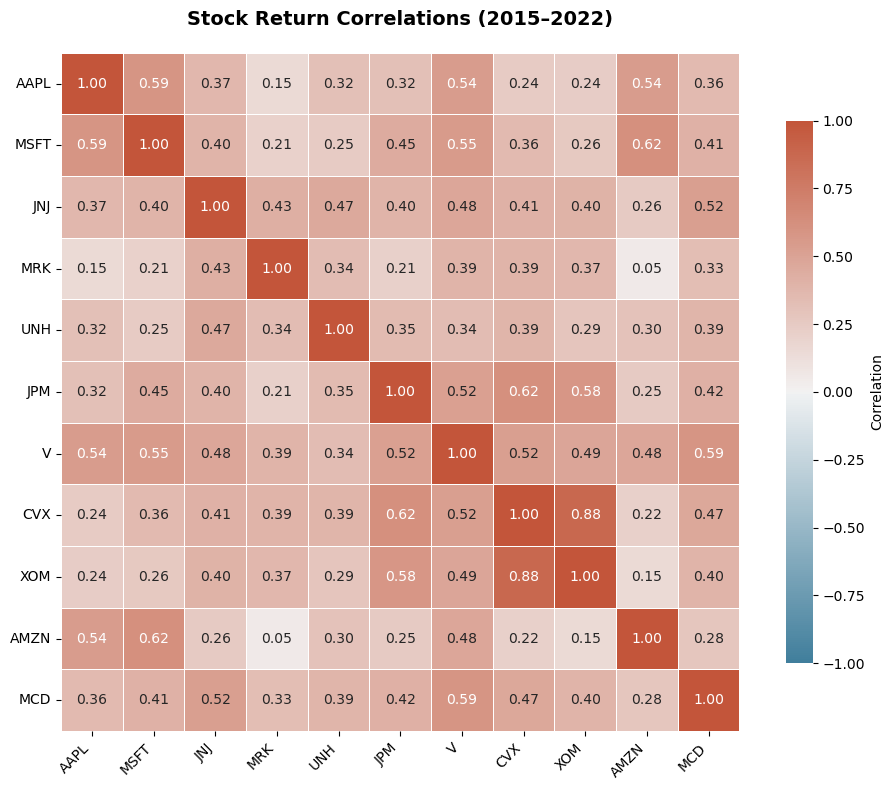

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

custom_cmap = sns.diverging_palette(230, 20, as_cmap=True)

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    sample_corr, 
    cmap=custom_cmap, 
    vmin=-1, 
    vmax=1,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    square=True,
    xticklabels=STOCKS, 
    yticklabels=STOCKS,
    cbar_kws={'label': 'Correlation', 'shrink': 0.8},
    ax=ax
)

ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_title("Stock Return Correlations (2015–2022)", pad=20, fontsize=14, fontweight="bold")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "T3_stock_correlation_heatmap_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


The covariance and correlation matrices show how the selected stocks have historically moved together.

Lower correlations may provide diversification benefits, while highly correlated stocks offer less risk reduction when combined.

These relationships will be used in portfolio optimization to evaluate whether stock-level diversification can reduce the risk observed in the original sector selection.


## 9. Single Index Model

The Single Index Model assumes that stock returns are influenced by overall market movements and company-specific factors.

The regression equation is:

$$
R_{i,t}-R_{f,t}=\alpha_i+\beta_i(R_{m,t}-R_{f,t})+\varepsilon_{i,t}
$$

where:

- $\alpha_i$: Return unexplained by market movements.
- $\beta_i$: Sensitivity to market returns.
- $\varepsilon_i$: Company-specific return component.

SPY represents the market, while the risk-free rate comes from Kenneth French's data.

The model estimates covariance as:

$$
\operatorname{Cov}(R_i,R_j)=\beta_i\beta_j\sigma_m^2
$$

For each stock, total variance also includes residual variance:

$$
\sigma_i^2=\beta_i^2\sigma_m^2+\sigma_{\varepsilon_i}^2
$$

Compared with sample covariance, this approach requires fewer estimates but assumes company-specific residuals are uncorrelated.

In [31]:
import statsmodels.api as sm

# Calculate monthly excess returns.

market_excess = monthly_returns["SPY"] - rf
stock_excess = monthly_returns[STOCKS].sub(rf, axis=0)

if stock_excess.isna().any().any() or market_excess.isna().any():
    raise ValueError("Missing excess return observations.")

# Estimate the Single Index Model for each stock.

sim_results = []
betas = []
residual_variances = []

X = sm.add_constant(
    market_excess.rename("Market Excess")
)

for ticker in STOCKS:

    model = sm.OLS(stock_excess[ticker], X).fit()

    alpha = model.params["const"]
    beta = model.params["Market Excess"]

    residual_var = model.mse_resid

    betas.append(beta)
    residual_variances.append(residual_var)

    sim_results.append({
        "Ticker": ticker,
        "Alpha (Monthly)": alpha,
        "Beta": beta,
        "R-squared": model.rsquared,
        "Residual Std (Monthly)": np.sqrt(residual_var),
        "Beta p-value": model.pvalues["Market Excess"]
    })

sim_summary = pd.DataFrame(sim_results).set_index("Ticker")

display(sim_summary.round(4))

sim_summary.to_csv(
    TABLES_DIR / "T3_single_index_regression.csv"
)

print("Single Index regressions completed.")


,Alpha (Monthly),Beta,R-squared,Residual Std (Monthly),Beta p-value
Ticker,,,,,
AAPL,0.0096,1.2541,0.4702,0.0616,0.0000
MSFT,0.0115,1.0161,0.5178,0.0454,0.0000
JNJ,0.0032,0.5722,0.3407,0.0368,0.0000
MRK,0.0073,0.4485,0.1321,0.0532,0.0003
UNH,0.0138,0.7042,0.3017,0.0496,0.0000
JPM,0.0025,1.1677,0.5377,0.0501,0.0000
V,0.0057,0.9652,0.5383,0.0414,0.0000
CVX,0.0011,1.2005,0.4352,0.0633,0.0000
XOM,-0.0004,1.0507,0.3342,0.0686,0.0000


Single Index regressions completed.


In [34]:
# Annualize the market and residual variances.

betas = np.array(betas)
residual_variances = np.array(residual_variances)

market_variance = market_excess.var(ddof=1) * 12
residual_variances_annual = residual_variances * 12

# Systematic covariance + company-specific variance.

sim_cov_array = (
    np.outer(betas, betas) * market_variance
    + np.diag(residual_variances_annual)
)

sim_cov = pd.DataFrame(
    sim_cov_array,
    index=STOCKS,
    columns=STOCKS
)

display(sim_cov.round(4))

sim_cov.to_csv(
    TABLES_DIR / "T3_single_index_covariance.csv"
)

print("Single Index covariance matrix calculated.")
print("Matrix dimensions:", sim_cov.shape)


,AAPL,MSFT,JNJ,MRK,UNH,JPM,V,CVX,XOM,AMZN,MCD
AAPL,0.0855,0.0324,0.0182,0.0143,0.0225,0.0372,0.0308,0.0383,0.0335,0.0395,0.0211
MSFT,0.0324,0.0509,0.0148,0.0116,0.0182,0.0302,0.0249,0.0310,0.0271,0.0320,0.0171
JNJ,0.0182,0.0148,0.0246,0.0065,0.0102,0.0170,0.0140,0.0175,0.0153,0.0180,0.0096
MRK,0.0143,0.0116,0.0065,0.0391,0.0080,0.0133,0.0110,0.0137,0.0120,0.0141,0.0075
UNH,0.0225,0.0182,0.0102,0.0080,0.0421,0.0209,0.0173,0.0215,0.0188,0.0222,0.0118
JPM,0.0372,0.0302,0.0170,0.0133,0.0209,0.0648,0.0287,0.0356,0.0312,0.0368,0.0196
V,0.0308,0.0249,0.0140,0.0110,0.0173,0.0287,0.0442,0.0295,0.0258,0.0304,0.0162
CVX,0.0383,0.0310,0.0175,0.0137,0.0215,0.0356,0.0295,0.0847,0.0321,0.0378,0.0202
XOM,0.0335,0.0271,0.0153,0.0120,0.0188,0.0312,0.0258,0.0321,0.0846,0.0331,0.0176
AMZN,0.0395,0.0320,0.0180,0.0141,0.0222,0.0368,0.0304,0.0378,0.0331,0.1029,0.0208


Single Index covariance matrix calculated.
Matrix dimensions: (11, 11)


In [35]:
# Compare individual stock volatility estimates.

risk_comparison = pd.DataFrame({
    "Sample Volatility": np.sqrt(np.diag(sample_cov)),
    "Single Index Volatility": np.sqrt(np.diag(sim_cov))
}, index=STOCKS)

risk_comparison["Difference"] = (
    risk_comparison["Single Index Volatility"]
    - risk_comparison["Sample Volatility"]
)

display(risk_comparison.round(4))

risk_comparison.to_csv(
    TABLES_DIR / "T3_covariance_model_comparison.csv"
)

# Compare covariance estimates directly.
covariance_difference = sim_cov - sample_cov

comparison_summary = pd.DataFrame({
    "Metric": [
        "Average Absolute Covariance Difference",
        "Maximum Absolute Covariance Difference"
    ],
    "Value": [
        covariance_difference.abs().to_numpy().mean(),
        covariance_difference.abs().to_numpy().max()
    ]
})

display(comparison_summary.round(6))


,Sample Volatility,Single Index Volatility,Difference
AAPL,0.2913,0.2924,0.0011
MSFT,0.2250,0.2257,0.0007
JNJ,0.1561,0.1568,0.0008
MRK,0.1970,0.1976,0.0006
UNH,0.2040,0.2052,0.0012
JPM,0.2539,0.2545,0.0006
V,0.2098,0.2103,0.0005
CVX,0.2898,0.2910,0.0012
XOM,0.2894,0.2908,0.0014
AMZN,0.3192,0.3207,0.0016


,Metric,Value
0,Average Absolute Covariance Difference,0.0059
1,Maximum Absolute Covariance Difference,0.0415



### Comparison of Covariance Models

The Sample Covariance Matrix directly estimates historical relationships between stock returns.

The Single Index Model estimates these relationships through market beta and company-specific residual risk.

Both approaches provide estimates of portfolio risk, but they may produce different covariance values and portfolio weights.

The next stage will apply both models to the same candidate universe and compare their effects on portfolio optimization, Sharpe Ratio, and risk-return utility.

## 10. Maximum Sharpe Ratio Portfolio

The Maximum Sharpe Ratio Portfolio identifies the risky asset combination offering the highest expected excess return per unit of total risk.

The Sharpe Ratio is:

$$
SR_p=\frac{E(R_p)-R_f}{\sigma_p}
$$

where:

- $E(R_p)$ is the expected annual portfolio return.
- $R_f$ is the annualized risk-free rate.
- $\sigma_p$ is annualized portfolio volatility.

The objective is to maximize the Sharpe Ratio subject to the investment constraints.

The analysis compares the Sample Covariance Matrix and Single Index Model using the same candidate assets.


In [36]:
# Final optimization universe: 11 stocks + IWM.
OPTIMIZATION_ASSETS = STOCKS + ["IWM"]

# Sample covariance for all investment candidates.
sample_cov_full = (
    monthly_returns[OPTIMIZATION_ASSETS].cov() * 12
)

# Estimate the Single Index parameters for IWM.
iwm_excess = monthly_returns["IWM"] - rf

X_iwm = sm.add_constant(
    market_excess.rename("Market Excess")
)

iwm_model = sm.OLS(iwm_excess, X_iwm).fit()

iwm_beta = iwm_model.params["Market Excess"]
iwm_residual_variance = iwm_model.mse_resid

# Existing stock betas and residual variances
stock_betas = sim_summary.loc[STOCKS, "Beta"].to_numpy()

stock_residual_var = (
    sim_summary.loc[
        STOCKS, "Residual Std (Monthly)"
    ].to_numpy() ** 2
)

all_betas = np.append(stock_betas, iwm_beta)

all_residual_var = np.append(
    stock_residual_var,
    iwm_residual_variance
)

# Construct the annualized Single Index covariance matrix.
sim_cov_full_array = (
    np.outer(all_betas, all_betas) * market_variance
    + np.diag(all_residual_var * 12)
)

sim_cov_full = pd.DataFrame(
    sim_cov_full_array,
    index=OPTIMIZATION_ASSETS,
    columns=OPTIMIZATION_ASSETS
)

assert sample_cov_full.shape == (12, 12)
assert sim_cov_full.shape == (12, 12)

sample_cov_full.to_csv(
    TABLES_DIR / "T3_sample_covariance_full.csv"
)

sim_cov_full.to_csv(
    TABLES_DIR / "T3_single_index_covariance_full.csv"
)

print("Both covariance matrices contain 12 investment candidates.")


Both covariance matrices contain 12 investment candidates.


In [ ]:
# Estimate expected returns using only 2015–2022 data.
mu = (
    monthly_returns[OPTIMIZATION_ASSETS].mean() * 12
)

# Annualize the average monthly risk-free return.
RF_ANNUAL = rf.mean() * 12

# SPY benchmark estimates.
SPY_RETURN = monthly_returns["SPY"].mean() * 12
SPY_VOLATILITY = (
    monthly_returns["SPY"].std(ddof=1) * np.sqrt(12)
)

SPY_SHARPE = (
    SPY_RETURN - RF_ANNUAL
) / SPY_VOLATILITY

expected_returns_table = pd.DataFrame({
    "Expected Annual Return": mu,
    "Annual Volatility": (
        monthly_returns[OPTIMIZATION_ASSETS].std()
        * np.sqrt(12)
    )
})

display(expected_returns_table)

print(f"Annual risk-free rate: {RF_ANNUAL:.4%}")
print(f"SPY Sharpe Ratio: {SPY_SHARPE:.4f}")

,Expected Annual Return,Annual Volatility
AAPL,0.2501,0.2913
MSFT,0.2488,0.2250
JNJ,0.1048,0.1561
MRK,0.1407,0.1970
UNH,0.2444,0.2040
JPM,0.1557,0.2539
V,0.1735,0.2098
CVX,0.1427,0.2898
XOM,0.1091,0.2894
AMZN,0.2622,0.3192


Annual risk-free rate: 0.8475%
SPY Sharpe Ratio: 0.6310


In [41]:

from scipy.optimize import minimize

MAX_WEIGHT = 0.15

def portfolio_statistics(weights, expected_returns, covariance):
    """Calculate annual portfolio return and volatility."""

    expected_return = float(weights @ expected_returns)

    variance = float(
        weights @ covariance @ weights
    )

    volatility = np.sqrt(max(variance, 0.0))

    return expected_return, volatility


def portfolio_sharpe(weights, expected_returns, covariance, rf_annual):
    """Calculate expected annual Sharpe Ratio."""

    expected_return, volatility = portfolio_statistics(
        weights, expected_returns, covariance
    )

    if volatility <= 0:
        return -np.inf

    return (expected_return - rf_annual) / volatility


def optimize_sharpe(expected_returns, covariance, rf_annual):

    n = len(expected_returns)

    result = minimize(
        lambda w: -portfolio_sharpe(
            w, expected_returns, covariance, rf_annual
        ),
        x0=np.repeat(1 / n, n),
        method="SLSQP",
        bounds=[(0, MAX_WEIGHT)] * n,
        constraints=[{
            "type": "eq",
            "fun": lambda w: np.sum(w) - 1
        }],
        options={
            "maxiter": 5000,
            "ftol": 1e-12
        }
    )

    if not result.success:
        raise RuntimeError(result.message)

    return result.x


def optimize_utility(expected_returns, covariance, A):

    n = len(expected_returns)

    def negative_utility(weights):

        expected_return, volatility = portfolio_statistics(
            weights, expected_returns, covariance
        )

        return -(
            expected_return - 0.5 * A * volatility**2
        )

    result = minimize(
        negative_utility,
        x0=np.repeat(1 / n, n),
        method="SLSQP",
        bounds=[(0, MAX_WEIGHT)] * n,
        constraints=[{
            "type": "eq",
            "fun": lambda w: np.sum(w) - 1
        }],
        options={
            "maxiter": 5000,
            "ftol": 1e-12
        }
    )

    if not result.success:
        raise RuntimeError(result.message)

    return result.x

print("Portfolio optimization functions ready.")


Portfolio optimization functions ready.


In [42]:
# Calculate Maximum Sharpe portfolios under both risk models.

RISK_MODELS = {
    "Sample Covariance": sample_cov_full.to_numpy(),
    "Single Index": sim_cov_full.to_numpy()
}

mu_array = mu.to_numpy()

max_sharpe_weights = {}
max_sharpe_results = []

for model_name, covariance in RISK_MODELS.items():

    weights = optimize_sharpe(
        mu_array,
        covariance,
        RF_ANNUAL
    )

    expected_return, volatility = portfolio_statistics(
        weights, mu_array, covariance
    )

    max_sharpe_weights[model_name] = weights

    max_sharpe_results.append({
        "Model": model_name,
        "Expected Return": expected_return,
        "Volatility": volatility,
        "Sharpe Ratio": (
            expected_return - RF_ANNUAL
        ) / volatility
    })

max_sharpe_comparison = pd.DataFrame(max_sharpe_results)

display(max_sharpe_comparison)

pd.DataFrame(
    max_sharpe_weights,
    index=OPTIMIZATION_ASSETS
).to_csv(
    TABLES_DIR / "T3_max_sharpe_weights.csv",
    index_label="Ticker"
)

max_sharpe_comparison.to_csv(
    TABLES_DIR / "T3_max_sharpe_comparison.csv",
    index=False
)


,Model,Expected Return,Volatility,Sharpe Ratio
0,Sample Covariance,0.2025,0.1493,1.2990
1,Single Index,0.1953,0.1424,1.3124


The Maximum Sharpe Portfolio identifies the asset combination with the highest estimated excess return relative to total volatility.

Differences between the two optimized portfolios arise from their covariance estimates, since expected returns and investment constraints are identical.

The results help evaluate the effect of risk modeling on portfolio selection.



## 11. Mean Variance Optimization

Mean-variance optimization selects portfolio weights by balancing expected return against total portfolio variance.

The objective is:

$$
\max U_p=E(R_p)-\frac{A}{2}\sigma_p^2
$$

where $A$ represents the investor's risk-aversion coefficient.

Three values are examined:

- $A=1$: Lower risk aversion.
- $A=3$: Moderate risk aversion.
- $A=5$: Higher risk aversion.

Both covariance models are tested under identical expected-return assumptions and investment constraints.


In [43]:
RISK_AVERSION_LEVELS = [1, 3, 5]

utility_results = []
utility_weights = {}

for model_name, covariance in RISK_MODELS.items():

    for A in RISK_AVERSION_LEVELS:

        weights = optimize_utility(
            mu_array,
            covariance,
            A
        )

        expected_return, volatility = portfolio_statistics(
            weights, mu_array, covariance
        )

        sharpe = (
            expected_return - RF_ANNUAL
        ) / volatility

        utility = (
            expected_return - 0.5 * A * volatility**2
        )

        portfolio_name = f"{model_name} | A={A}"

        utility_weights[portfolio_name] = weights

        utility_results.append({
            "Portfolio": portfolio_name,
            "Model": model_name,
            "Risk Aversion": A,
            "Expected Return": expected_return,
            "Volatility": volatility,
            "Sharpe Ratio": sharpe,
            "Utility": utility
        })

utility_comparison = pd.DataFrame(utility_results)

display(utility_comparison.round(4))

utility_comparison.to_csv(
    TABLES_DIR / "T3_mean_variance_comparison.csv",
    index=False
)

utility_weights_table = pd.DataFrame(
    utility_weights,
    index=OPTIMIZATION_ASSETS
)

utility_weights_table.to_csv(
    TABLES_DIR / "T3_mean_variance_weights.csv",
    index_label="Ticker"
)

display(utility_weights_table.round(4))


,Portfolio,Model,Risk Aversion,Expected Return,Volatility,Sharpe Ratio,Utility
0,Sample Covariance | A=1,Sample Covariance,1,0.2179,0.1706,1.2280,0.2034
1,Sample Covariance | A=3,Sample Covariance,3,0.2150,0.1606,1.2856,0.1763
2,Sample Covariance | A=5,Sample Covariance,5,0.2143,0.1595,1.2904,0.1507
3,Single Index | A=1,Single Index,1,0.2169,0.1646,1.2665,0.2034
4,Single Index | A=3,Single Index,3,0.2161,0.1618,1.2837,0.1769
5,Single Index | A=5,Single Index,5,0.2150,0.1596,1.2941,0.1513


,Sample Covariance | A=1,Sample Covariance | A=3,Sample Covariance | A=5,Single Index | A=1,Single Index | A=3,Single Index | A=5
AAPL,0.1500,0.1500,0.1500,0.1500,0.1500,0.1500
MSFT,0.1500,0.1500,0.1500,0.1500,0.1500,0.1500
JNJ,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
MRK,0.0126,0.1500,0.1500,0.0789,0.1138,0.1500
UNH,0.1500,0.1500,0.1500,0.1500,0.1500,0.1500
JPM,0.0874,0.0000,0.0395,0.0211,0.0000,0.0000
V,0.1500,0.1000,0.0605,0.1500,0.1362,0.1000
CVX,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
XOM,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
AMZN,0.1500,0.1500,0.1500,0.1500,0.1500,0.1500


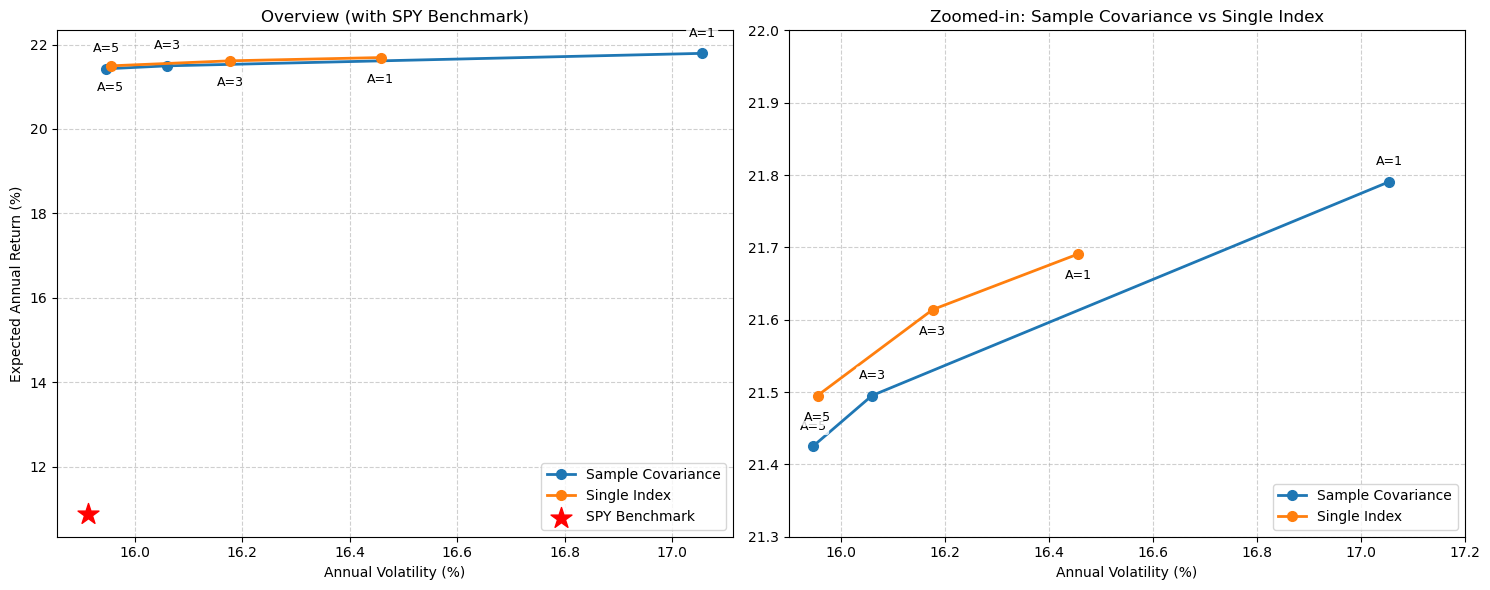

In [48]:
import matplotlib.pyplot as plt

# Create 2 subplots side-by-side: 1 overview, 1 zoomed-in
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

for ax in [ax1, ax2]:
    ax.grid(True, linestyle='--', alpha=0.6)
    
    for idx, model_name in enumerate(RISK_MODELS):
        data = utility_comparison[utility_comparison["Model"] == model_name]
        
        ax.plot(
            data["Volatility"] * 100, data["Expected Return"] * 100,
            marker="o", markersize=7, linewidth=2, label=model_name
        )
        
        # Adjust dynamic offset to prevent label overlapping
        y_offset = 12 if idx == 0 else -18 
        for _, row in data.iterrows():
            ax.annotate(
                f"A={int(row['Risk Aversion'])}",
                (row["Volatility"] * 100, row["Expected Return"] * 100),
                xytext=(0, y_offset), textcoords="offset points",
                ha='center', fontsize=9,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8, ec="none")
            )

# Subplot 1: Overview (Includes SPY Benchmark)
ax1.scatter(SPY_VOLATILITY * 100, SPY_RETURN * 100, marker="*", s=250, color='red', label="SPY Benchmark")
ax1.set_title("Overview (with SPY Benchmark)")
ax1.set_xlabel("Annual Volatility (%)")
ax1.set_ylabel("Expected Annual Return (%)")
ax1.legend(loc='lower right')

# Subplot 2: Zoomed-in on the 2 model curves
ax2.set_title("Zoomed-in: Sample Covariance vs Single Index")
ax2.set_xlabel("Annual Volatility (%)")
# Set X and Y limits to zoom closely into the two lines
ax2.set_xlim(15.9, 17.2) 
ax2.set_ylim(21.3, 22.0)
ax2.legend(loc='lower right')

plt.tight_layout()
fig.savefig(FIGURES_DIR / "T3_mean_variance_tradeoff_zoomed.png", dpi=300)
plt.show()

In [49]:
# Combine the results into one comparison table.

max_sharpe_table = max_sharpe_comparison.copy()
max_sharpe_table["Portfolio"] = (
    max_sharpe_table["Model"] + " | Max Sharpe"
)
max_sharpe_table["Risk Aversion"] = np.nan
max_sharpe_table["Utility at A=3"] = (
    max_sharpe_table["Expected Return"]
    - 0.5 * 3 * max_sharpe_table["Volatility"]**2
)

mv_table = utility_comparison.copy()
mv_table["Utility at A=3"] = (
    mv_table["Expected Return"]
    - 0.5 * 3 * mv_table["Volatility"]**2
)

final_comparison = pd.concat([
    max_sharpe_table,
    mv_table
], ignore_index=True)

final_comparison = final_comparison[
    [
        "Portfolio",
        "Expected Return",
        "Volatility",
        "Sharpe Ratio",
        "Utility at A=3"
    ]
]

display(final_comparison.round(4))

final_comparison.to_csv(
    TABLES_DIR / "T3_optimization_comparison.csv",
    index=False
)


,Portfolio,Expected Return,Volatility,Sharpe Ratio,Utility at A=3
0,Sample Covariance | Max Sharpe,0.2025,0.1493,1.2990,0.1690
1,Single Index | Max Sharpe,0.1953,0.1424,1.3124,0.1649
2,Sample Covariance | A=1,0.2179,0.1706,1.2280,0.1743
3,Sample Covariance | A=3,0.2150,0.1606,1.2856,0.1763
4,Sample Covariance | A=5,0.2143,0.1595,1.2904,0.1761
5,Single Index | A=1,0.2169,0.1646,1.2665,0.1763
6,Single Index | A=3,0.2161,0.1618,1.2837,0.1769
7,Single Index | A=5,0.2150,0.1596,1.2941,0.1768



### Preliminary Portfolio Selection

The team selects the Single Index Model with A = 3 as the recommended portfolio because it achieves the highest utility of 0.1769 among the eight portfolios, under the long-only, fully invested, and maximum 15% individual asset weight constraints.

This portfolio provides an expected annual return of 21.61%, volatility of 16.18%, and Sharpe Ratio of 1.2837. Compared with the Sample Covariance portfolio at A = 3, it offers a slightly higher return and utility, despite a small increase in risk.

Although the Maximum Sharpe portfolio has a higher Sharpe Ratio, it delivers lower utility at A = 3. Since Kappa aims to balance investment growth with risk tolerance rather than maximize Sharpe Ratio alone, the Single Index portfolio with A = 3 is the preferred choice under the team's assumptions and constraints.

This recommendation will be later tested through sensitivity analysis and downside-risk evaluation.

## 12. Risk Aversion Sensitivity Analysis

The purpose of this analysis is to examine how changes in risk aversion affect optimal portfolio allocation.

The optimization results for A = 1, 3, and 5 have already been calculated in Section 11. Therefore, this section focuses on changes in portfolio weights rather than repeating the return and risk comparison.

A lower risk-aversion coefficient places greater emphasis on expected returns, while a higher coefficient gives more importance to reducing portfolio variance.

We compare the portfolio weights under both the Sample Covariance and Single Index models to assess the stability of the selected allocation.

In [56]:
sample_weights = utility_weights_table[
    [
        "Sample Covariance | A=1",
        "Sample Covariance | A=3",
        "Sample Covariance | A=5"
    ]
].copy()

single_index_weights = utility_weights_table[
    [
        "Single Index | A=1",
        "Single Index | A=3",
        "Single Index | A=5"
    ]
].copy()

sample_weights.columns = ["A=1", "A=3", "A=5"]
single_index_weights.columns = ["A=1", "A=3", "A=5"]

print("Sample Covariance Portfolio Weights:")
display(sample_weights.round(4))

print("Single Index Portfolio Weights:")
display(single_index_weights.round(4))

sample_weights.to_csv(
    TABLES_DIR / "T3_sample_risk_aversion_weights.csv",
    index_label="Ticker"
)

single_index_weights.to_csv(
    TABLES_DIR / "T3_single_index_risk_aversion_weights.csv",
    index_label="Ticker"
)

Sample Covariance Portfolio Weights:


,A=1,A=3,A=5
AAPL,0.1500,0.1500,0.1500
MSFT,0.1500,0.1500,0.1500
JNJ,0.0000,0.0000,0.0000
MRK,0.0126,0.1500,0.1500
UNH,0.1500,0.1500,0.1500
JPM,0.0874,0.0000,0.0395
V,0.1500,0.1000,0.0605
CVX,0.0000,0.0000,0.0000
XOM,0.0000,0.0000,0.0000
AMZN,0.1500,0.1500,0.1500


Single Index Portfolio Weights:


,A=1,A=3,A=5
AAPL,0.1500,0.1500,0.1500
MSFT,0.1500,0.1500,0.1500
JNJ,0.0000,0.0000,0.0000
MRK,0.0789,0.1138,0.1500
UNH,0.1500,0.1500,0.1500
JPM,0.0211,0.0000,0.0000
V,0.1500,0.1362,0.1000
CVX,0.0000,0.0000,0.0000
XOM,0.0000,0.0000,0.0000
AMZN,0.1500,0.1500,0.1500


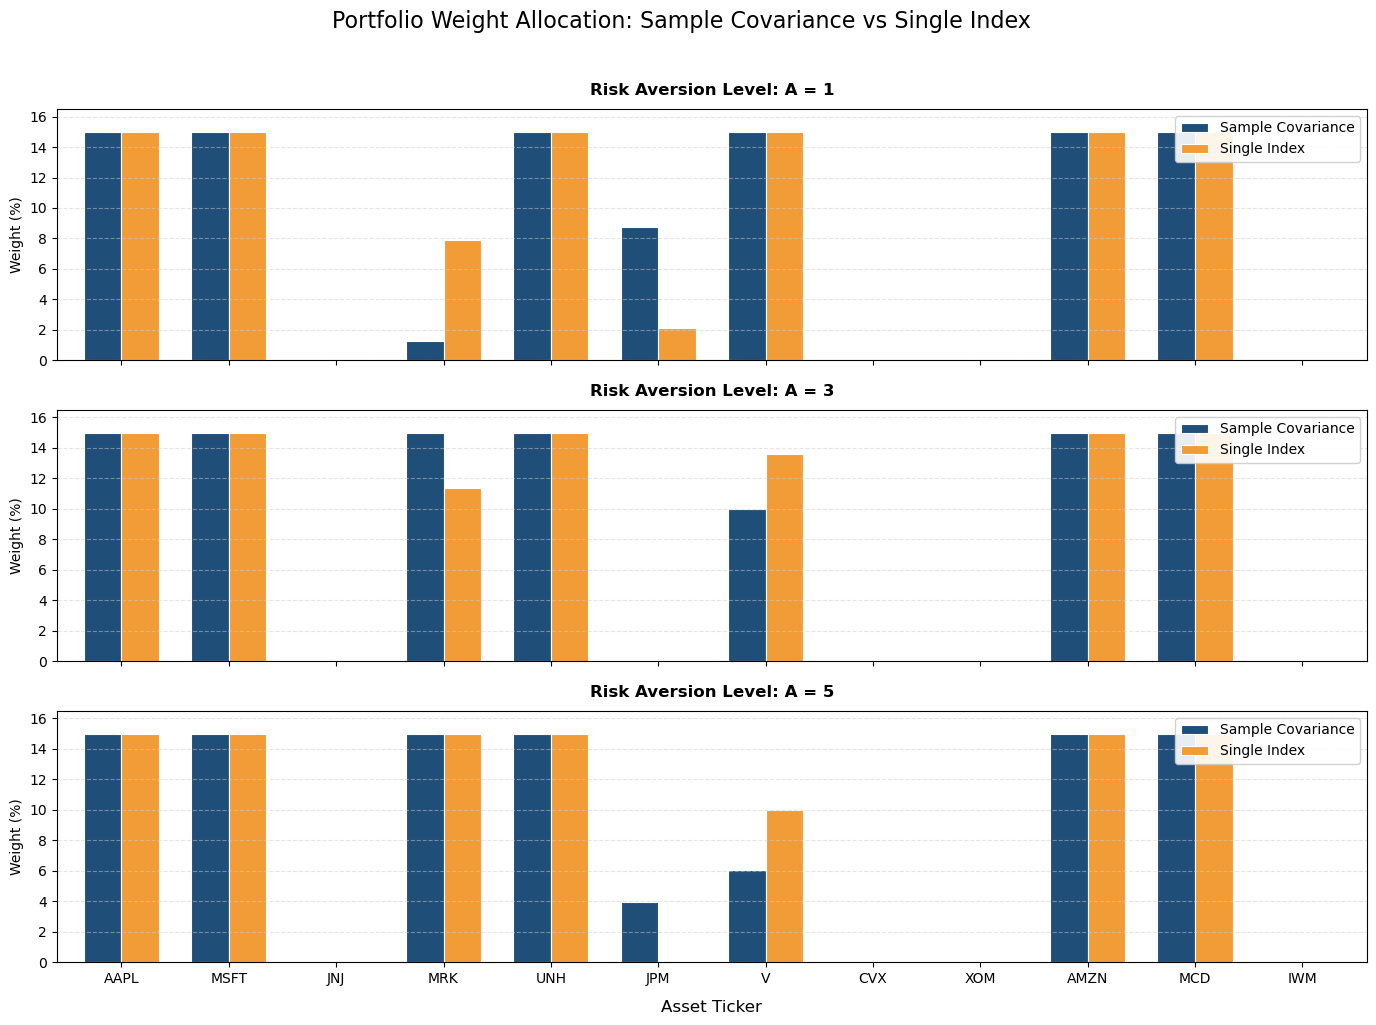

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Prepare the data structure
comparison_weights = pd.DataFrame(index=OPTIMIZATION_ASSETS)

for A in [1, 3, 5]:
    comparison_weights[f"Sample A={A}"] = utility_weights_table[f"Sample Covariance | A={A}"]
    comparison_weights[f"SIM A={A}"] = utility_weights_table[f"Single Index | A={A}"]

# Convert weights to percentages
comparison_pct = comparison_weights * 100

# Create 3 subplots sharing the same X-axis
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(14, 10), sharex=True)

risk_levels = [1, 3, 5]

# Updated Colors: Navy Blue and Vibrant Orange/Gold
colors = ['#1f4e79', '#f29c38'] 

for i, A in enumerate(risk_levels):
    ax = axes[i]
    
    # Filter data for the current risk aversion level
    subset = comparison_pct[[f"Sample A={A}", f"SIM A={A}"]]
    
    # Plot bars with the new color scheme
    subset.plot.bar(
        ax=ax, 
        width=0.7, # Slightly wider bars to fill space better
        color=colors,
        edgecolor='white', # White edges make the colors pop against each other
        linewidth=0.8
    )
    
    # Formatting each subplot
    ax.set_title(f"Risk Aversion Level: A = {A}", fontsize=12, fontweight='bold', pad=10)
    ax.set_ylabel("Weight (%)", fontsize=10)
    ax.grid(axis="y", linestyle='--', alpha=0.5, color='#cccccc') # Lighter, softer gridlines
    
    # Standardize Y-axis limits
    ax.set_ylim(0, max(comparison_pct.max().max() * 1.1, 15)) 
    
    # Clean up legends
    ax.legend(["Sample Covariance", "Single Index"], loc="upper right", framealpha=0.9)

# Format the shared X-axis on the bottom plot only
axes[-1].set_xlabel("Asset Ticker", fontsize=12, labelpad=10)
axes[-1].set_xticklabels(comparison_pct.index, rotation=0, ha="center")

# Overall title
fig.suptitle("Portfolio Weight Allocation: Sample Covariance vs Single Index", fontsize=16, y=1.02)

plt.tight_layout()

# Save
fig.savefig(
    FIGURES_DIR / "T3_combined_risk_aversion_weights_subplots_new_colors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [59]:
# Measure how much portfolio allocation changes relative to A = 3.

def portfolio_weight_change(weights_a, weights_b):
    """Calculate the minimum portfolio weight reallocation."""
    return 0.5 * np.abs(weights_a - weights_b).sum()


allocation_changes = []

for model_name, weights_table in [
    ("Sample Covariance", sample_weights),
    ("Single Index", single_index_weights)
]:

    base_weights = weights_table["A=3"].to_numpy()

    for level in ["A=1", "A=5"]:

        comparison_weights = weights_table[level].to_numpy()

        allocation_changes.append({
            "Risk Model": model_name,
            "Comparison": f"{level} vs A=3",
            "Weight Reallocation":
                portfolio_weight_change(
                    comparison_weights,
                    base_weights
                )
        })

allocation_change_table = pd.DataFrame(allocation_changes)

display(allocation_change_table.round(4))

allocation_change_table.to_csv(
    TABLES_DIR / "T3_risk_aversion_weight_changes.csv",
    index=False
)


,Risk Model,Comparison,Weight Reallocation
0,Sample Covariance,A=1 vs A=3,0.1374
1,Sample Covariance,A=5 vs A=3,0.0395
2,Single Index,A=1 vs A=3,0.0349
3,Single Index,A=5 vs A=3,0.0362


The results support the selection of the Single Index Model with A = 3. When risk aversion changes from A = 1 to A = 3, the Single Index portfolio requires only 3.49% weight reallocation, compared with 13.74% for Sample Covariance. Changes from A = 3 to A = 5 are also small for both models.

The selected portfolio achieves the highest reported utility of 0.1769, with an expected return of 21.61% and volatility of 16.18%. Therefore, it offers a reasonable balance between risk, return, and allocation stability under the chosen constraints, although concentration risk remains.

## 13. Risk Tolerance Assessment

Kappa Foundation is concerned about investment losses approaching 15%.

The team proposes a risk limit where the probability of losing 15% or more over one year should not exceed 5%.

$$
P(R_p \leq -15\%) \leq 5\%
$$

We use one-year 95% Value at Risk (VaR) under the normal distribution assumption:

$$
VaR_{95\%}=1.645\sigma_p-E(R_p)
$$

A VaR of 15% or less indicates that the portfolio meets the proposed limit under this assumption.

The assessment first examines the recommended growth portfolio and then considers its contribution to total foundation risk. VaR is an estimate rather than a guarantee against investment losses.

In [62]:
from scipy.stats import norm

# Recommended portfolio: Single Index Model, A = 3.
recommended_weights = utility_weights["Single Index | A=3"]

expected_return, volatility = portfolio_statistics(
    recommended_weights,
    mu_array,
    sim_cov_full.to_numpy()
)

LOSS_LIMIT = 0.15
CONFIDENCE_LEVEL = 0.95

z_score = norm.ppf(CONFIDENCE_LEVEL)

# One-year parametric Value at Risk.
growth_var = z_score * volatility - expected_return

# Probability of losing at least 15%.
growth_loss_probability = norm.cdf(
    (-LOSS_LIMIT - expected_return) / volatility
)

growth_risk = pd.DataFrame({
    "Metric": [
        "Expected Annual Return",
        "Annual Volatility",
        "95% VaR",
        "Probability of Loss >= 15%",
        "Maximum Allowed Loss Probability"
    ],
    "Value": [
        expected_return,
        volatility,
        growth_var,
        growth_loss_probability,
        0.05
    ]
})

display(growth_risk.round(4))

print(f"Growth Portfolio VaR: {growth_var:.2%}")
print(f"Probability of losing 15% or more: {growth_loss_probability:.2%}")

if growth_loss_probability <= 0.05:
    print("Growth portfolio PASSES the proposed VaR condition.")
else:
    print("Growth portfolio FAILS the proposed VaR condition.")

growth_risk.to_csv(
    TABLES_DIR / "T3_growth_portfolio_var.csv",
    index=False
)


,Metric,Value
0,Expected Annual Return,0.2161
1,Annual Volatility,0.1618
2,95% VaR,0.0500
3,Probability of Loss >= 15%,0.0118
4,Maximum Allowed Loss Probability,0.0500


Growth Portfolio VaR: 5.00%
Probability of losing 15% or more: 1.18%
Growth portfolio PASSES the proposed VaR condition.


In [64]:
import json

# Load liability funding results from Task 2.
with open(
    PROCESSED_DIR / "task2_funding_results.json",
    "r",
    encoding="utf-8"
) as file:
    funding = json.load(file)

initial_wealth = funding["initial_wealth_usd"]
growth_capital = funding["growth_capital_usd"]
funding_capital = funding["funding_cost_usd"]

growth_weight = growth_capital / initial_wealth
funding_weight = funding_capital / initial_wealth

total_return = growth_weight * expected_return
total_volatility = growth_weight * volatility

total_var = z_score * total_volatility - total_return

total_loss_probability = norm.cdf(
    (-LOSS_LIMIT - total_return) / total_volatility
)

risk_comparison = pd.DataFrame({
    "Portfolio": ["Growth Portfolio", "Total Fund (Illustrative)"],
    "Expected Return": [expected_return, total_return],
    "Volatility": [volatility, total_volatility],
    "95% VaR": [growth_var, total_var],
    "Probability of Loss >= 15%": [
        growth_loss_probability,
        total_loss_probability
    ]
})

display(risk_comparison.round(4))

risk_comparison.to_csv(
    TABLES_DIR / "T3_risk_tolerance_comparison.csv",
    index=False
)

print(f"Growth allocation: {growth_weight:.2%}")
print(f"Liability funding allocation: {funding_weight:.2%}")
print(f"Illustrative total fund VaR: {total_var:.2%}")


,Portfolio,Expected Return,Volatility,95% VaR,Probability of Loss >= 15%
0,Growth Portfolio,0.2161,0.1618,0.0500,0.0118
1,Total Fund (Illustrative),0.1222,0.0914,0.0282,0.0015


Growth allocation: 56.53%
Liability funding allocation: 43.47%
Illustrative total fund VaR: 2.82%



### Risk Tolerance Interpretation

The recommended Single Index portfolio with A = 3 has an expected annual return of 21.61% and volatility of 16.18%. Its estimated 95% VaR is approximately 5.0%, below the proposed 15% loss limit.

## 14. Final Portfolio Allocation

The team recommends the Single Index Model with A = 3 for Kappa Foundation's growth allocation.

This portfolio achieves the highest reported utility of 0.1769 under the selected model and investment constraints, with an expected annual return of 21.61%, volatility of 16.18%, and Sharpe Ratio of 1.2837.

In [70]:
# Final allocation: Single Index Model, A = 3

import json

# Define the allocation output directory.
ALLOCATIONS_DIR = PROJECT_ROOT / "outputs" / "allocations"
ALLOCATIONS_DIR.mkdir(parents=True, exist_ok=True)

with open(PROCESSED_DIR / "task2_funding_results.json", "r") as f:
    funding = json.load(f)

initial_wealth = funding["initial_wealth_usd"]
funding_cost = funding["funding_cost_usd"]
growth_capital = funding["growth_capital_usd"]

weights = utility_weights["Single Index | A=3"]
transaction_rate = 0.001

# Include 0.10% transaction costs within the growth budget.
growth_investment = growth_capital / (1 + transaction_rate)
trading_cost = growth_investment * transaction_rate

allocation = pd.DataFrame({
    "Ticker": OPTIMIZATION_ASSETS,
    "Weight": weights,
    "Investment USD": weights * growth_investment
})

allocation["Trading Cost USD"] = (
    allocation["Investment USD"] * transaction_rate
)

allocation = allocation.sort_values(
    "Investment USD", ascending=False
)

# Full USD 12 million allocation
summary = pd.DataFrame({
    "Component": ["Bond Funding", "Growth Portfolio", "Trading Costs"],
    "Amount USD": [funding_cost, growth_investment, trading_cost]
})

display(allocation.round(4))
display(summary)

assert np.isclose(weights.sum(), 1)
assert np.isclose(summary["Amount USD"].sum(), initial_wealth)

# Save results for Task 4.
allocation.to_csv(
    ALLOCATIONS_DIR / "T3_final_growth_allocation.csv",
    index=False
)

summary.to_csv(
    TABLES_DIR / "T3_final_allocation_summary.csv",
    index=False
)

with open(PROCESSED_DIR / "task3_portfolio_results.json", "w") as f:
    json.dump({
        "model": "Single Index",
        "risk_aversion": 3,
        "benchmark": "SPY",
        "asset_weights": dict(zip(
            OPTIMIZATION_ASSETS, [float(w) for w in weights]
        )),
        "growth_investment_usd": float(growth_investment),
        "funding_cost_usd": float(funding_cost),
        "transaction_cost_usd": float(trading_cost)
    }, f, indent=4)

print(f"Total allocated: ${summary['Amount USD'].sum():,.2f}")
print("Allocation verified and exported.")


,Ticker,Weight,Investment USD,Trading Cost USD
0,AAPL,0.1500,"1,016,468.9609","1,016.4690"
1,MSFT,0.1500,"1,016,468.9609","1,016.4690"
9,AMZN,0.1500,"1,016,468.9609","1,016.4690"
4,UNH,0.1500,"1,016,468.9609","1,016.4690"
10,MCD,0.1500,"1,016,468.9609","1,016.4690"
6,V,0.1362,"923,156.0163",923.1560
3,MRK,0.1138,"770,958.9185",770.9589
2,JNJ,0.0000,0.0000,0.0000
5,JPM,0.0000,0.0000,0.0000
7,CVX,0.0000,0.0000,0.0000


,Component,Amount USD
0,Bond Funding,"5,216,763.8009"
1,Growth Portfolio,"6,776,459.7394"
2,Trading Costs,"6,776.4597"


Total allocated: $12,000,000.00
Allocation verified and exported.


In [72]:
import plotly.express as px

# Convert the pandas Series to a DataFrame for Plotly
df_plot = plot_values.reset_index()
df_plot.columns = ['Category', 'Amount']

# Generate a Donut Chart
fig = px.pie(
    df_plot, 
    values='Amount', 
    names='Category', 
    hole=0.4, 
    title="Kappa Foundation: Initial USD 12 Million Allocation"
)

# Format the hover data and text labels
fig.update_traces(
    textposition='inside', 
    textinfo='percent+label',
    hovertemplate="<b>%{label}</b><br>Amount: $%{value:,.2f}<br>Share: %{percent}<extra></extra>"
)

fig.show()